### Coursework 1

Session 683257169: 296 cells, VISp, 205 um, Slc17a7-IRES2-Cre, GCaMP6s, 30.08 Hz, 64.0 min
           stimulus      start       stop
  drifting_gratings   36.88669  636.35644
natural_movie_three  667.40372 1267.87545
  natural_movie_one 1297.92577 1598.13058
  drifting_gratings 1628.18105 2227.66457
        spontaneous 2232.65088 2528.87140
natural_movie_three 2528.90464 3129.39497
  drifting_gratings 3159.41301 3842.95113


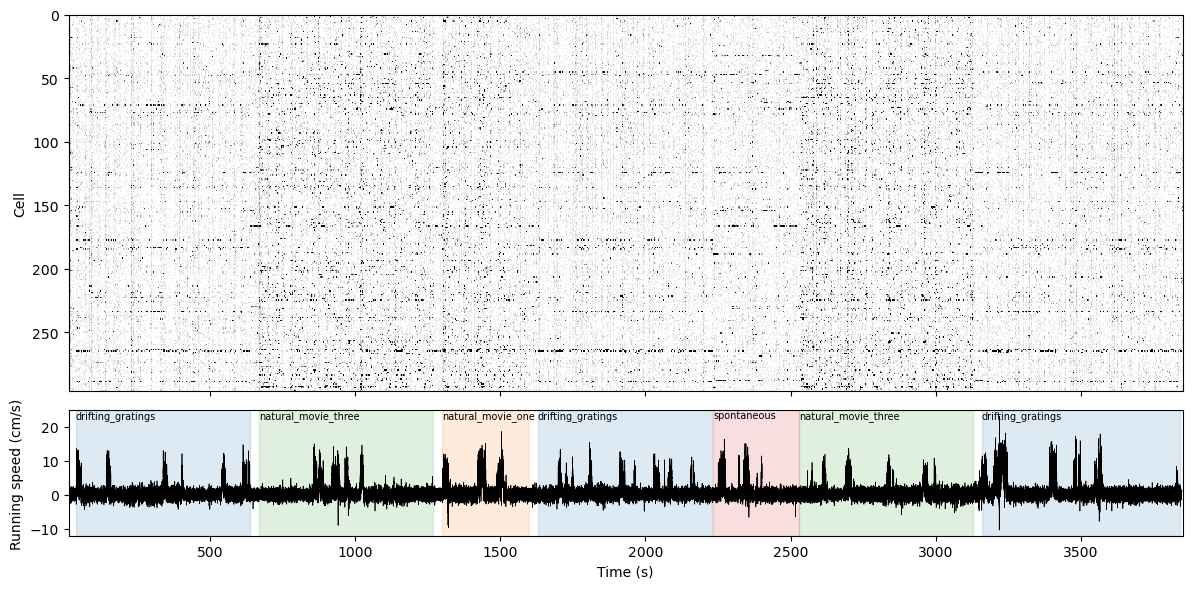

In [2]:
import json
import sys

import numpy as np
import pandas as pd

def load_session(path):
    z = np.load(path)
    d = {k: z[k] for k in ("dff", "t", "running_speed", "movie_frame", "cell_ids")}
    d["movie_trials"] = pd.DataFrame(z["movie_trials"], columns=["start", "stop"])
    gt = pd.DataFrame(z["grating_trials"], columns=list(z["grating_columns"]))
    gt["is_blank"] = gt["is_blank"].astype(bool)
    d["grating_trials"] = gt
    d["epochs"] = pd.DataFrame({
        "stimulus": z["epoch_names"],
        "start": z["epoch_times"][:, 0],
        "stop": z["epoch_times"][:, 1],
    })
    d["meta"] = json.loads(str(z["meta"]))
    return d


def frames_between(t, start, stop):
    """Boolean mask selecting imaging frames with start <= t < stop."""
    return (t >= start) & (t < stop)


if __name__ == "__main__":
    import matplotlib.pyplot as plt

    d = load_session("coursework1_data.npz")
    m = d["meta"]
    print(f"Session {m['session_id']}: {m['n_cells']} cells, {m['area']}, {m['imaging_depth_um']} um, "
          f"{m['cre_line']}, {m['indicator']}, {m['frame_rate_hz']:.2f} Hz, {m['duration_s'] / 60:.1f} min")
    print(d["epochs"].to_string(index=False))

    fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
    ax[0].imshow(d["dff"], aspect="auto", cmap="gray_r", vmin=0, vmax=np.nanpercentile(d["dff"], 99),
                 extent=[d["t"][0], d["t"][-1], d["dff"].shape[0], 0], interpolation="none")
    ax[0].set_ylabel("Cell")
    ax[1].plot(d["t"], d["running_speed"], lw=0.5, color="k")
    ax[1].set_ylabel("Running speed (cm/s)")
    ax[1].set_xlabel("Time (s)")
    kinds = sorted(d["epochs"]["stimulus"].unique())
    for _, e in d["epochs"].iterrows():
        ax[1].axvspan(e["start"], e["stop"], alpha=0.15, color="C%d" % kinds.index(e["stimulus"]))
        ax[1].text(e["start"], ax[1].get_ylim()[1], e["stimulus"], fontsize=7, va="top")
    fig.tight_layout()
    plt.show()
